# CO₂ Emissions Analysis

Cleaning Our World in Data's CO₂ dataset and exploring how emissions per person relate to income across countries.

Individual course project for MIS 515 (Programming Data-Driven Applications), San Diego State University, Fall 2025. Data: [Our World in Data CO₂ and Greenhouse Gas Emissions](https://github.com/owid/co2-data).

## 1. Setup and download

In [1]:
# MIS 515 - Project 1: Data Cleaning & Visualization (OWID CO₂)

DATA_DIR = "data"
RAW_DIR = f"{DATA_DIR}/raw"
PROC_DIR = f"{DATA_DIR}/processed"
FIG_DIR = "figures"

# Our World in Data's CO₂ dataset (downloaded fresh on every run)
OWID_CO2_CSV_URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Just creating folders
for d in [DATA_DIR, RAW_DIR, PROC_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

In [2]:
# Download the dataset (original one)
from datetime import date

df_raw = pd.read_csv(OWID_CO2_CSV_URL)
raw_path = f"{RAW_DIR}/owid-co2-data_original.csv"
df_raw.to_csv(raw_path, index=False)
print("Downloaded:", date.today(), "| rows:", len(df_raw))

Downloaded: 2026-10-18 | rows: 50411


## 2. Check data quality

The duplicate (iso_code, year) count comes from regional aggregates such as World and EU, which have no ISO code. They drop out in step 3, and real countries have no duplicates.

In [3]:
df_raw.info()

# Checking missing values (using top 20 columns)
missing = df_raw.isna().sum().sort_values(ascending=False)
print(missing.head(20))

# Checking duplicate rows
dupe_count = df_raw.duplicated(subset=['iso_code','year']).sum()
print("Duplicate (iso_code, year) rows:", dupe_count)



<class 'pandas.DataFrame'>
RangeIndex: 50411 entries, 0 to 50410
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    50411 non-null  str    
 1   year                                       50411 non-null  int64  
 2   iso_code                                   42480 non-null  str    
 3   population                                 41167 non-null  float64
 4   gdp                                        15251 non-null  float64
 5   cement_co2                                 29173 non-null  float64
 6   cement_co2_per_capita                      25648 non-null  float64
 7   co2                                        29384 non-null  float64
 8   co2_growth_abs                             27216 non-null  float64
 9   co2_growth_prct                            26239 non-null  float64
 10  co2_including_luc                

## 3. Clean the data

Countries only (3-letter ISO codes, so aggregates like World and EU drop out), GDP per capita engineered, and each country's latest year with complete CO₂, GDP and population data.

In [4]:
df = df_raw.copy()

# keep countries only since I don't want to include stuff like "World" or "EU"
df = df[df['iso_code'].astype(str).str.len() == 3].copy()

# just trying to be safe and make sure data are numeric type
for c in ['year', 'population']:
    if c in df: df[c] = pd.to_numeric(df[c], errors='coerce')

# gdp per capita (for plots later, PLEASE REMEMBER)
if {'gdp','population'}.issubset(df.columns):
    df['gdp_per_capita'] = df['gdp'] / df['population']

# The plots might break if missing some core fields, this should prevent it
need = ['co2_per_capita','gdp_per_capita','population']
df_core = df.dropna(subset=[c for c in need if c in df])

# latest year per country (what I intend on using for this project view)
df_core = df_core.sort_values(['iso_code','year'])
df_latest = df_core.drop_duplicates('iso_code', keep='last').copy()

# keep only columns I'll use (not really needed but I want the dataframe to be smaller)
cols = [
    'iso_code','country','continent','year','population',
    'co2','co2_per_capita','gdp','gdp_per_capita',
    'coal_co2','oil_co2','gas_co2','cement_co2','flaring_co2',
    'methane','nitrous_oxide','primary_energy_consumption','energy_per_capita'
]
cols = [c for c in cols if c in df_latest]
df_clean = df_latest[cols].copy()

# ALWAYS strip whitespaces, this has messed up far too many of my previous work
if 'continent' in df_clean:
    df_clean['continent'] = df_clean['continent'].astype('string').str.strip()

# saving the cleaned file for submission
clean_path = f"{PROC_DIR}/owid-co2-data_clean_latest_year.csv"
df_clean.to_csv(clean_path, index=False)
print("Saved:", clean_path, "| rows:", len(df_clean))


Saved: data/processed/owid-co2-data_clean_latest_year.csv | rows: 164


## 4. Distribution of CO₂ per capita

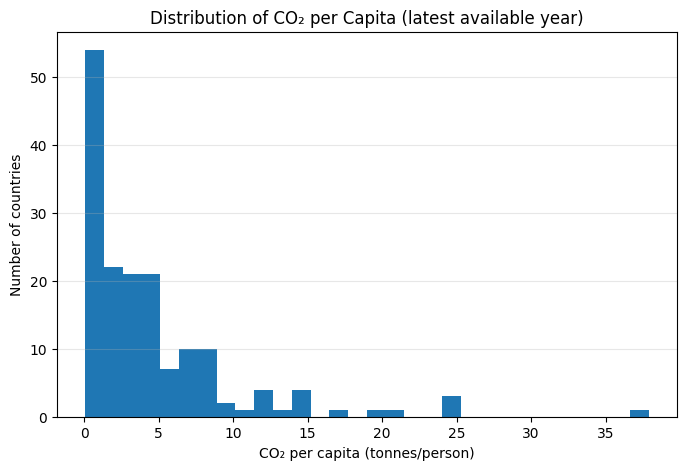

In [5]:
#Histogram of CO₂ per capita (latest year)

plt.figure(figsize=(8,5))
plt.hist(df_clean['co2_per_capita'].dropna(), bins=30) #Took me 20 minutes to realize this, REMEMBER to drop missing values in the future
plt.title("Distribution of CO₂ per Capita (latest available year)")
plt.xlabel("CO₂ per capita (tonnes/person)")
plt.ylabel("Number of countries")
plt.grid(axis='y', alpha=0.3) #Common habit, it's just so much easier to read the plot with this
plt.savefig(f"{FIG_DIR}/hist_co2_per_capita.png", dpi=150)
plt.show()


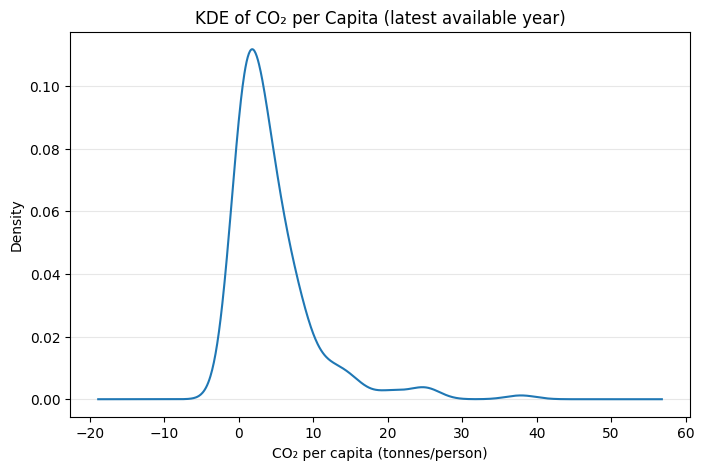

In [6]:
#Density of CO₂ per capita (using Kernel Density Estimate plot from pandas)

ax = df_clean['co2_per_capita'].plot(kind='kde', figsize=(8,5))
ax.set_title("KDE of CO₂ per Capita (latest available year)")
ax.set_xlabel("CO₂ per capita (tonnes/person)")
ax.grid(axis='y', alpha=0.3)
plt.savefig(f"{FIG_DIR}/kde_co2_per_capita.png", dpi=150)
plt.show()

## 5. Income vs emissions

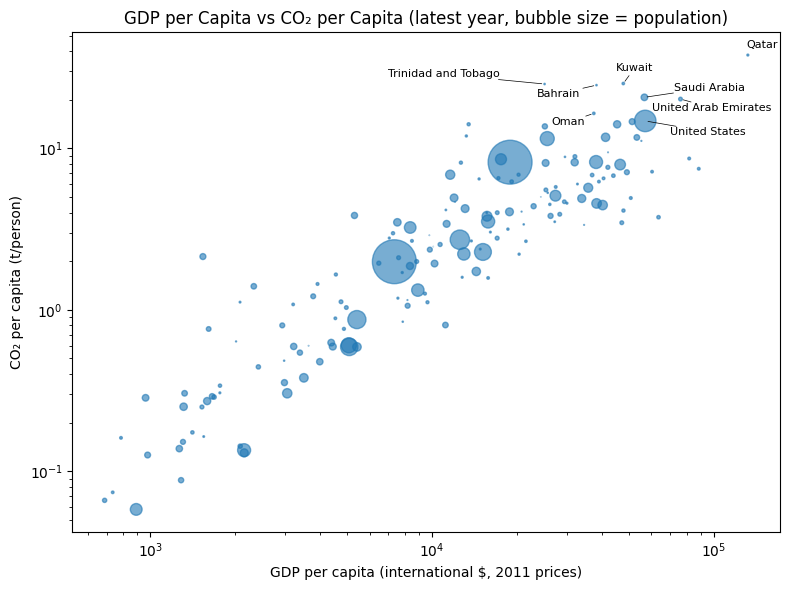

In [7]:
#Scatter: GDP per capita vs CO₂ per capita (bubble by population)
plot_df = df_clean[['gdp_per_capita','co2_per_capita','population','country']].dropna() #Again, took me a while to realize I need to drop the missing values
plot_df = plot_df[(plot_df['gdp_per_capita']>0) & (plot_df['co2_per_capita']>0)]  # the values can't be negative or zero, so this is to filter that out

x = plot_df['gdp_per_capita']
y = plot_df['co2_per_capita']
size = (plot_df['population'] / plot_df['population'].max()) * 1000  # I scale the population with bubble scale size of 1000

plt.figure(figsize=(8,6))
plt.scatter(x, y, s=size, alpha=0.6)
plt.xscale('log'); plt.yscale('log') #Without this line, the graph looks very small and doesn't scale well because it can't scale with the wide range of values
plt.xlabel("GDP per capita (international $, 2011 prices)")
plt.ylabel("CO₂ per capita (t/person)")
plt.title("GDP per Capita vs CO₂ per Capita (latest year, bubble size = population)")

# Labeled a few top countries
lab = plot_df.nlargest(8, 'co2_per_capita') # I labeled the top 8 countries with the highest CO₂ per capita for better presentation
texts = [plt.text(r['gdp_per_capita'], r['co2_per_capita'], r['country'], fontsize=8)
         for _, r in lab.iterrows()]

# adjust_text keeps the labels from overlapping, this part especially took longer to figure out
from adjustText import adjust_text
adjust_text(texts, expand=(1.6, 1.8), arrowprops=dict(arrowstyle='-', lw=0.5))

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/scatter_gdp_pc_vs_co2_pc_bubble.png", dpi=150)
plt.show()


In [8]:
# How strong is the relationship? Correlation on the log scale (the same scale as the chart)
r = np.corrcoef(np.log10(plot_df['gdp_per_capita']), np.log10(plot_df['co2_per_capita']))[0, 1]
print(f"Countries plotted: {len(plot_df)} | latest year: {df_clean['year'].max()}")
print(f"Correlation of log GDP per capita and log CO₂ per capita: r = {r:.2f}")
print("\nHighest CO₂ per capita (t/person):")
print(plot_df.nlargest(8, 'co2_per_capita')[['country', 'co2_per_capita']].round(1).to_string(index=False))

Countries plotted: 164 | latest year: 2022
Correlation of log GDP per capita and log CO₂ per capita: r = 0.91

Highest CO₂ per capita (t/person):
             country  co2_per_capita
               Qatar            37.9
              Kuwait            25.2
 Trinidad and Tobago            25.1
             Bahrain            24.7
        Saudi Arabia            20.7
United Arab Emirates            20.2
                Oman            16.5
       United States            14.8


## Results

Data downloaded on 18 Oct 2026; the latest year with complete CO₂, GDP and population data is 2022, covering **164 countries**.

- **Income and emissions move together.** On the log scale, GDP per capita and CO₂ per capita correlate at **r = 0.91**. That is a strong association, not proof that one causes the other.
- **Most countries emit little per person.** The median is 2.84 t per person and 71% of countries emit under 5 t, so the distribution is strongly right-skewed (histogram and KDE).
- **The top emitters per person are mostly oil and gas producers:** Qatar (37.9 t), Kuwait (25.2 t), Trinidad and Tobago (25.1 t), Bahrain, Saudi Arabia, the UAE and Oman. The United States (14.8 t) is the only large economy in the top 8.

Next steps: compare continents (the dataset has no continent column, so this needs a country-to-continent mapping), track change over time instead of a single year, and fit a regression line to find countries far above or below the trend.